<a href="https://colab.research.google.com/github/Siyagour26/Datheon-Machine-Learning---Data-Science-Internship/blob/internship-task-2/Task_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import fetch_california_housing

from sklearn.model_selection import train_test_split, GridSearchCV

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LinearRegression, Ridge, Lasso

from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    r2_score
)

In [3]:
df = pd.read_csv('housing.csv')
df.head()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY


In [6]:
# df.shape
# df.info()
# df.describe()
df.isnull().sum()
(df.isnull().sum() / len(df)) * 100

,0
longitude,0.000000
latitude,0.000000
housing_median_age,0.000000
total_rooms,0.000000
total_bedrooms,1.002907
population,0.000000
households,0.000000
median_income,0.000000
median_house_value,0.000000
ocean_proximity,0.000000


In [8]:
df.drop_duplicates(inplace=True)

In [9]:
df.describe()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value
count,20640.000000,20640.000000,20640.000000,20640.000000,20433.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,-119.569704,35.631861,28.639486,2635.763081,537.870553,1425.476744,499.539680,3.870671,206855.816909
std,2.003532,2.135952,12.585558,2181.615252,421.385070,1132.462122,382.329753,1.899822,115395.615874
min,-124.350000,32.540000,1.000000,2.000000,1.000000,3.000000,1.000000,0.499900,14999.000000
25%,-121.800000,33.930000,18.000000,1447.750000,296.000000,787.000000,280.000000,2.563400,119600.000000
50%,-118.490000,34.260000,29.000000,2127.000000,435.000000,1166.000000,409.000000,3.534800,179700.000000
75%,-118.010000,37.710000,37.000000,3148.000000,647.000000,1725.000000,605.000000,4.743250,264725.000000
max,-114.310000,41.950000,52.000000,39320.000000,6445.000000,35682.000000,6082.000000,15.000100,500001.000000


In [11]:
df.columns

Index(['longitude', 'latitude', 'housing_median_age', 'total_rooms',
       'total_bedrooms', 'population', 'households', 'median_income',
       'median_house_value', 'ocean_proximity'],
      dtype='object')

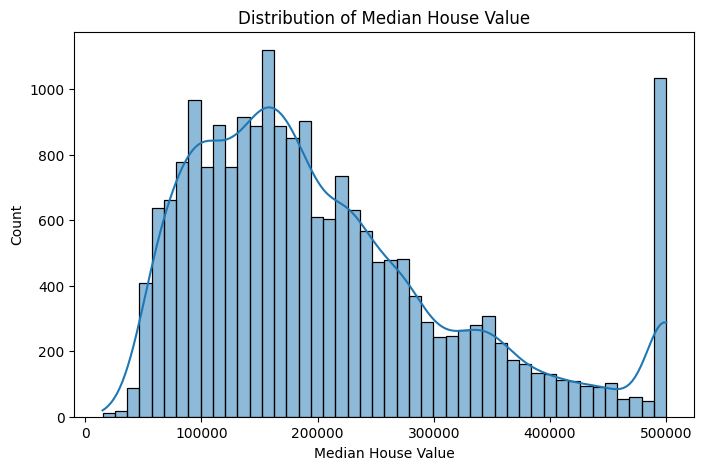

In [12]:
plt.figure(figsize=(8, 5))

sns.histplot(df['median_house_value'], kde=True)

plt.title('Distribution of Median House Value')
plt.xlabel('Median House Value')

plt.show()

In [13]:
df['ocean_proximity'].value_counts()

,count
ocean_proximity,
<1H OCEAN,9136
INLAND,6551
NEAR OCEAN,2658
NEAR BAY,2290
ISLAND,5


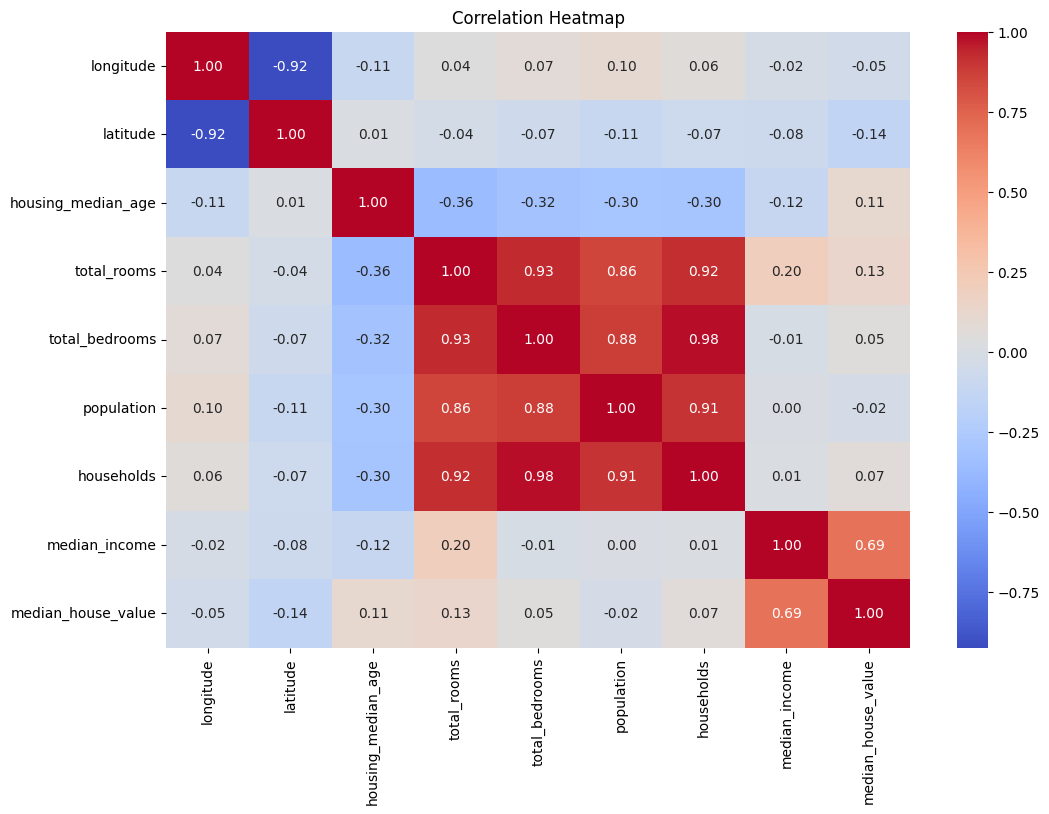

In [14]:
plt.figure(figsize=(12, 8))

sns.heatmap(
    df.corr(numeric_only=True),
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title('Correlation Heatmap')

plt.show()

In [15]:
X = df.drop('median_house_value', axis=1)

y = df['median_house_value']

In [18]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

In [19]:
num_cols = X.select_dtypes(include=np.number).columns

cat_cols = X.select_dtypes(include='object').columns

print("Numerical:", num_cols)
print("Categorical:", cat_cols)

Numerical: Index(['longitude', 'latitude', 'housing_median_age', 'total_rooms',
       'total_bedrooms', 'population', 'households', 'median_income'],
      dtype='object')
Categorical: Index(['ocean_proximity'], dtype='object')


In [20]:
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

In [21]:
num_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

In [22]:
cat_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

In [23]:
preprocessor = ColumnTransformer([
    ('num', num_pipeline, num_cols),
    ('cat', cat_pipeline, cat_cols)
])

In [24]:
X_train_processed = preprocessor.fit_transform(X_train)

X_test_processed = preprocessor.transform(X_test)

In [25]:
from sklearn.preprocessing import PolynomialFeatures

poly = PolynomialFeatures(
    degree=2,
    interaction_only=True,
    include_bias=False
)

X_train_interaction = poly.fit_transform(X_train_processed)

X_test_interaction = poly.transform(X_test_processed)

In [26]:
print("Before:", X_train_processed.shape)
print("After:", X_train_interaction.shape)

Before: (16512, 13)
After: (16512, 91)


In [27]:
from sklearn.linear_model import LinearRegression

ols = LinearRegression()

ols.fit(X_train_interaction, y_train)

ols_pred = ols.predict(X_test_interaction)

In [28]:
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

rmse = np.sqrt(mean_squared_error(y_test, ols_pred))

mae = mean_absolute_error(y_test, ols_pred)

r2 = r2_score(y_test, ols_pred)

print("OLS RMSE:", rmse)
print("OLS MAE:", mae)
print("OLS R2 Score:", r2)

OLS RMSE: 65664.64133395955
OLS MAE: 46124.72332347586
OLS R2 Score: 0.6709542445820393


In [29]:
from sklearn.linear_model import Ridge
from sklearn.model_selection import GridSearchCV

ridge = Ridge()

params = {
    'alpha': [0.001, 0.01, 0.1, 1, 10, 100, 1000]
}

ridge_grid = GridSearchCV(
    ridge,
    params,
    cv=5,
    scoring='neg_mean_squared_error',
    n_jobs=-1
)

ridge_grid.fit(X_train_interaction, y_train)

ridge_pred = ridge_grid.predict(X_test_interaction)

print("Best Alpha:", ridge_grid.best_params_)

Best Alpha: {'alpha': 0.001}


In [30]:
print("Ridge RMSE:", np.sqrt(mean_squared_error(y_test, ridge_pred)))

print("Ridge MAE:", mean_absolute_error(y_test, ridge_pred))

print("Ridge R2:", r2_score(y_test, ridge_pred))

Ridge RMSE: 65664.64918491732
Ridge MAE: 46124.68701253544
Ridge R2: 0.6709541658996789


In [33]:
lasso = Lasso(max_iter=5000, tol=0.001)

params = {
    'alpha': [0.001, 0.01, 0.1, 1, 10]
}

lasso_grid = GridSearchCV(
    lasso,
    params,
    cv=3,
    scoring='neg_mean_squared_error',
    n_jobs=-1
)

lasso_grid.fit(X_train_interaction, y_train)

lasso_pred = lasso_grid.predict(X_test_interaction)

print("Best Alpha:", lasso_grid.best_params_)

Best Alpha: {'alpha': 10}


/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_coordinate_descent.py:695: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 1.578e+13, tolerance: 2.207e+11
  model = cd_fast.enet_coordinate_descent(


In [34]:
print("Lasso RMSE:", np.sqrt(mean_squared_error(y_test, lasso_pred)))
print("Lasso MAE:", mean_absolute_error(y_test, lasso_pred))
print("Lasso R2:", r2_score(y_test, lasso_pred))

Lasso RMSE: 65461.49945309146
Lasso MAE: 46062.29168353733
Lasso R2: 0.6729869848419705


In [35]:
models = {
    'OLS': ols_pred,
    'Ridge': ridge_pred,
    'Lasso': lasso_pred
}

results = []

for name, pred in models.items():

    results.append({
        'Model': name,
        'RMSE': np.sqrt(mean_squared_error(y_test, pred)),
        'MAE': mean_absolute_error(y_test, pred),
        'R2 Score': r2_score(y_test, pred)
    })

results_df = pd.DataFrame(results)

results_df

,Model,RMSE,MAE,R2 Score
0,OLS,65664.641334,46124.723323,0.670954
1,Ridge,65664.649185,46124.687013,0.670954
2,Lasso,65461.499453,46062.291684,0.672987


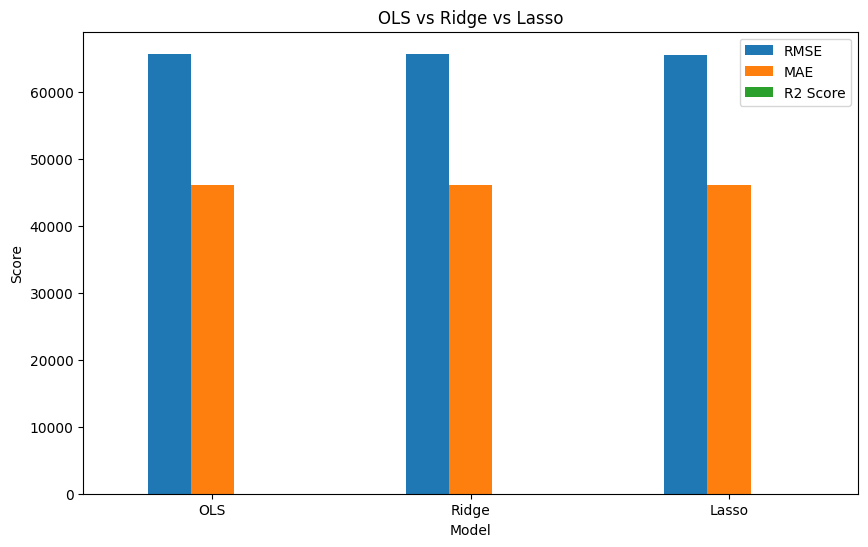

In [36]:
results_df.set_index('Model').plot(
    kind='bar',
    figsize=(10, 6)
)

plt.title('OLS vs Ridge vs Lasso')
plt.ylabel('Score')
plt.xticks(rotation=0)
plt.show()

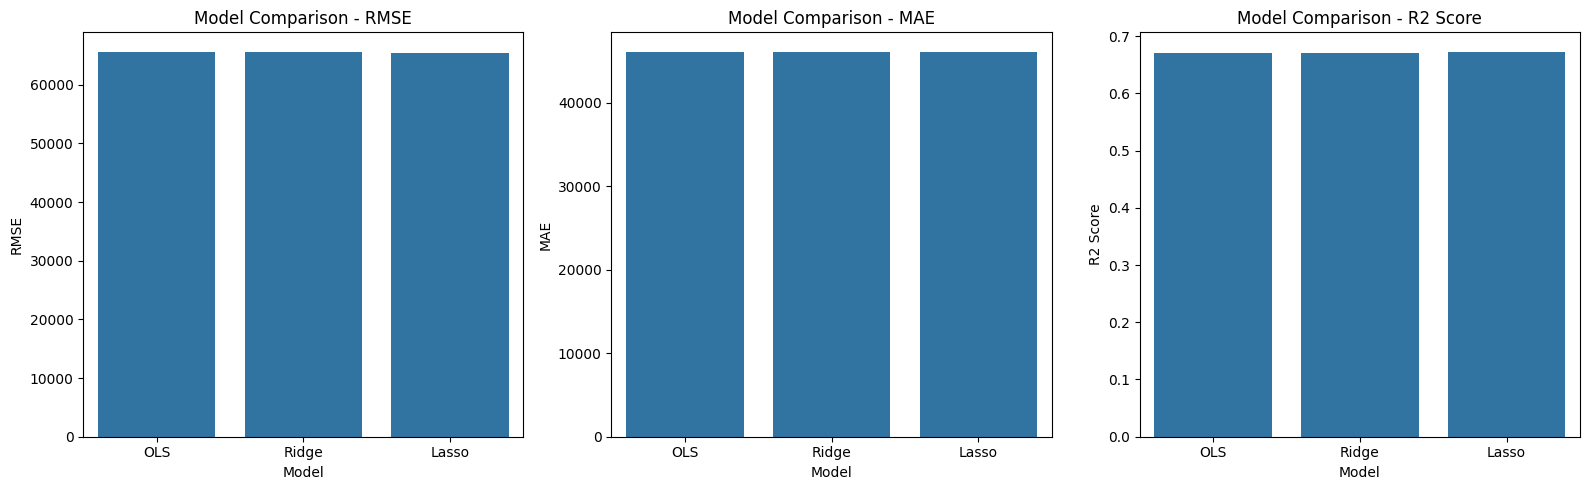

In [39]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

metrics = ['RMSE', 'MAE', 'R2 Score']

for ax, metric in zip(axes, metrics):

    sns.barplot(
        data=results_df,
        x='Model',
        y=metric,
        ax=ax
    )

    ax.set_title(f'Model Comparison - {metric}')

plt.tight_layout()
plt.show()

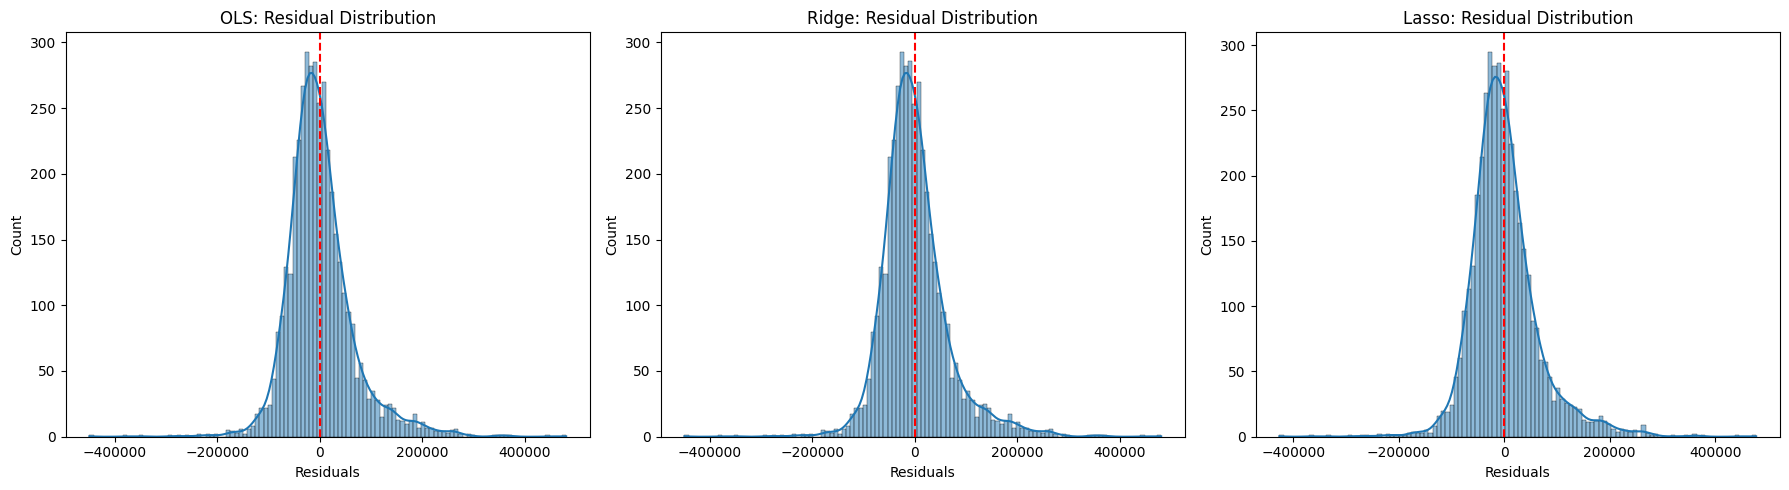

In [38]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, (name, pred) in zip(axes, models.items()):

    residuals = y_test - pred

    sns.histplot(residuals, kde=True, ax=ax)

    ax.axvline(0, color='red', linestyle='--')

    ax.set_title(f'{name}: Residual Distribution')
    ax.set_xlabel('Residuals')

plt.tight_layout()
plt.show()